# DSCI 552 Homework 4

**Name:** Shirley(Xue) Feng  
**GitHub Username:** snowxxxue 
**USC ID:** 7145149057

## 1. Time Series Classification Part 1: Feature Creation/Extraction

This section repeats the feature extraction work from Homework 3.
It is included to prepare the features used in Question 2.

#### 1(a)&(b)

In [1]:
from pathlib import Path
import re
import pandas as pd

data_dir = Path("data") / "AReM"

columns = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]

instances = []

for folder in sorted(data_dir.iterdir()):
    if not folder.is_dir():
        continue

    # Extract the dataset number so dataset10 comes after dataset9
    files = sorted(
        folder.glob("dataset*.csv"),
        key=lambda path: int(re.search(r"dataset(\d+)", path.stem).group(1))
    )

    for file_path in files:
        dataset_number = int(
            re.search(r"dataset(\d+)", file_path.stem).group(1)
        )

        # The CSV files start with comment lines. header=None preserves
        # the first numeric row as data instead of treating it as a header.
        df = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            names=columns,
            sep=r"\s*,\s*|\s+",
            engine="python",
            usecols=range(7)
        )
        is_bending_folder = folder.name in {"bending1", "bending2"}

        # Merge bending1 and bending2 into one activity label
        activity = "bending" if is_bending_folder else folder.name

        # Apply the required train/test split
        is_test = (
            (is_bending_folder and dataset_number in {1, 2})
            or (not is_bending_folder and dataset_number in {1, 2, 3})
        )

        instances.append({
            "folder": folder.name,
            "dataset": file_path.name,
            "activity": activity,
            "binary_label": "bending" if is_bending_folder else "other",
            "split": "test" if is_test else "train",
            "data": df,
        })

metadata = pd.DataFrame([
    {key: value for key, value in item.items() if key != "data"}
    for item in instances
])

print("Total instances:", len(instances))
print("Train instances:", (metadata["split"] == "train").sum())
print("Test instances:", (metadata["split"] == "test").sum())
display(metadata.groupby(["split", "activity"]).size().unstack(fill_value=0))

Total instances: 88
Train instances: 69
Test instances: 19


activity,bending,cycling,lying,sitting,standing,walking
split,,,,,,
test,4,3,3,3,3,3
train,9,12,12,12,12,12


#### 1(c)(i) Common Time-Domain Features

Time-domain features summarize the values or distribution of a time series over time. Common examples include the minimum, maximum, mean, median, variance, standard deviation, range, first and third quartiles, interquartile range, root mean square, skewness, and kurtosis.

#### 1(c)(ii) Extracted Features

For each of the 88 instances, I calculated the minimum, maximum, mean, median, standard deviation, first quartile, and third quartile for each of the six time series. This produced 42 features per instance.

In [2]:
statistics = ["min", "max", "mean", "median", "std", "q1", "q3"]
feature_rows = []

for item in instances:
    row = {
        "folder": item["folder"],
        "dataset": item["dataset"],
        "activity": item["activity"],
        "binary_label": item["binary_label"],
        "split": item["split"],
    }

    for series_number, column in enumerate(columns[1:], start=1):
        values = item["data"][column]

        row[f"min_{series_number}"] = values.min()
        row[f"max_{series_number}"] = values.max()
        row[f"mean_{series_number}"] = values.mean()
        row[f"median_{series_number}"] = values.median()
        row[f"std_{series_number}"] = values.std(ddof=1)
        row[f"q1_{series_number}"] = values.quantile(0.25)
        row[f"q3_{series_number}"] = values.quantile(0.75)

    feature_rows.append(row)

feature_df = pd.DataFrame(feature_rows)

feature_columns = [
    f"{stat}_{series_number}"
    for series_number in range(1, 7)
    for stat in statistics
]

print("Feature table shape:", feature_df.shape)
display(feature_df.head())

Feature table shape: (88, 47)


,folder,dataset,activity,binary_label,split,min_1,max_1,mean_1,median_1,std_1,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,bending1,dataset1.csv,bending,bending,test,37.25,45.00,40.624792,40.50,1.476967,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,dataset2.csv,bending,bending,test,38.00,45.67,42.812812,42.50,1.435550,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,dataset3.csv,bending,bending,train,35.00,47.40,43.954500,44.33,1.558835,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,dataset4.csv,bending,bending,train,33.00,47.75,42.179812,43.50,3.670666,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,dataset5.csv,bending,bending,train,33.00,45.75,41.678063,41.75,2.243490,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


#### 1(c)(iii) Standard Deviations and Bootstrap Confidence Intervals

For each feature, I calculated its sample standard deviation across the 88 instances. I then resampled the instance values with replacement 10,000 times and used the 5th and 95th percentiles of the bootstrap standard deviations as the 90% confidence interval.

In [3]:
import numpy as np

rng = np.random.default_rng(42)
n_bootstrap = 10000
summary_rows = []

for column in feature_columns:
    values = feature_df[column].to_numpy()

    observed_sd = np.std(values, ddof=1)

    bootstrap_samples = rng.choice(
        values,
        size=(n_bootstrap, len(values)),
        replace=True
    )
    bootstrap_sds = np.std(bootstrap_samples, axis=1, ddof=1)

    lower, upper = np.percentile(bootstrap_sds, [5, 95])

    summary_rows.append({
        "feature": column,
        "standard_deviation": observed_sd,
        "90% CI lower": lower,
        "90% CI upper": upper,
    })

sd_summary = pd.DataFrame(summary_rows)

display(sd_summary)

,feature,standard_deviation,90% CI lower,90% CI upper
0,min_1,9.569975,8.236003,10.773895
1,max_1,4.394362,3.329945,5.296590
2,mean_1,5.335718,4.688296,5.889086
3,median_1,5.440054,4.795819,5.987308
4,std_1,1.772153,1.574247,1.951729
5,q1_1,6.153590,5.575910,6.643478
6,q3_1,5.138925,4.326313,5.842674
7,min_2,0.000000,0.000000,0.000000
8,max_2,5.062729,4.631065,5.399928
9,mean_2,1.574164,1.392814,1.705984


#### 1(c)(iv) Selected Features

I selected the minimum, mean, and maximum as the three features. They summarize the lower values, the central level, and the upper values of each time series. I will use these features in the scatter plots in Question 2(a)(i).

#### 2(a)(i) Scatter Plots for the Training Set

I used the training set to compare bending with the other activities. For each instance, I extracted the minimum, mean, and maximum from time series 1, 2, and 6. The scatterplot matrix shows the pairwise relationships among these nine features. Each point represents one instance, and its color indicates whether it belongs to the bending or other class.

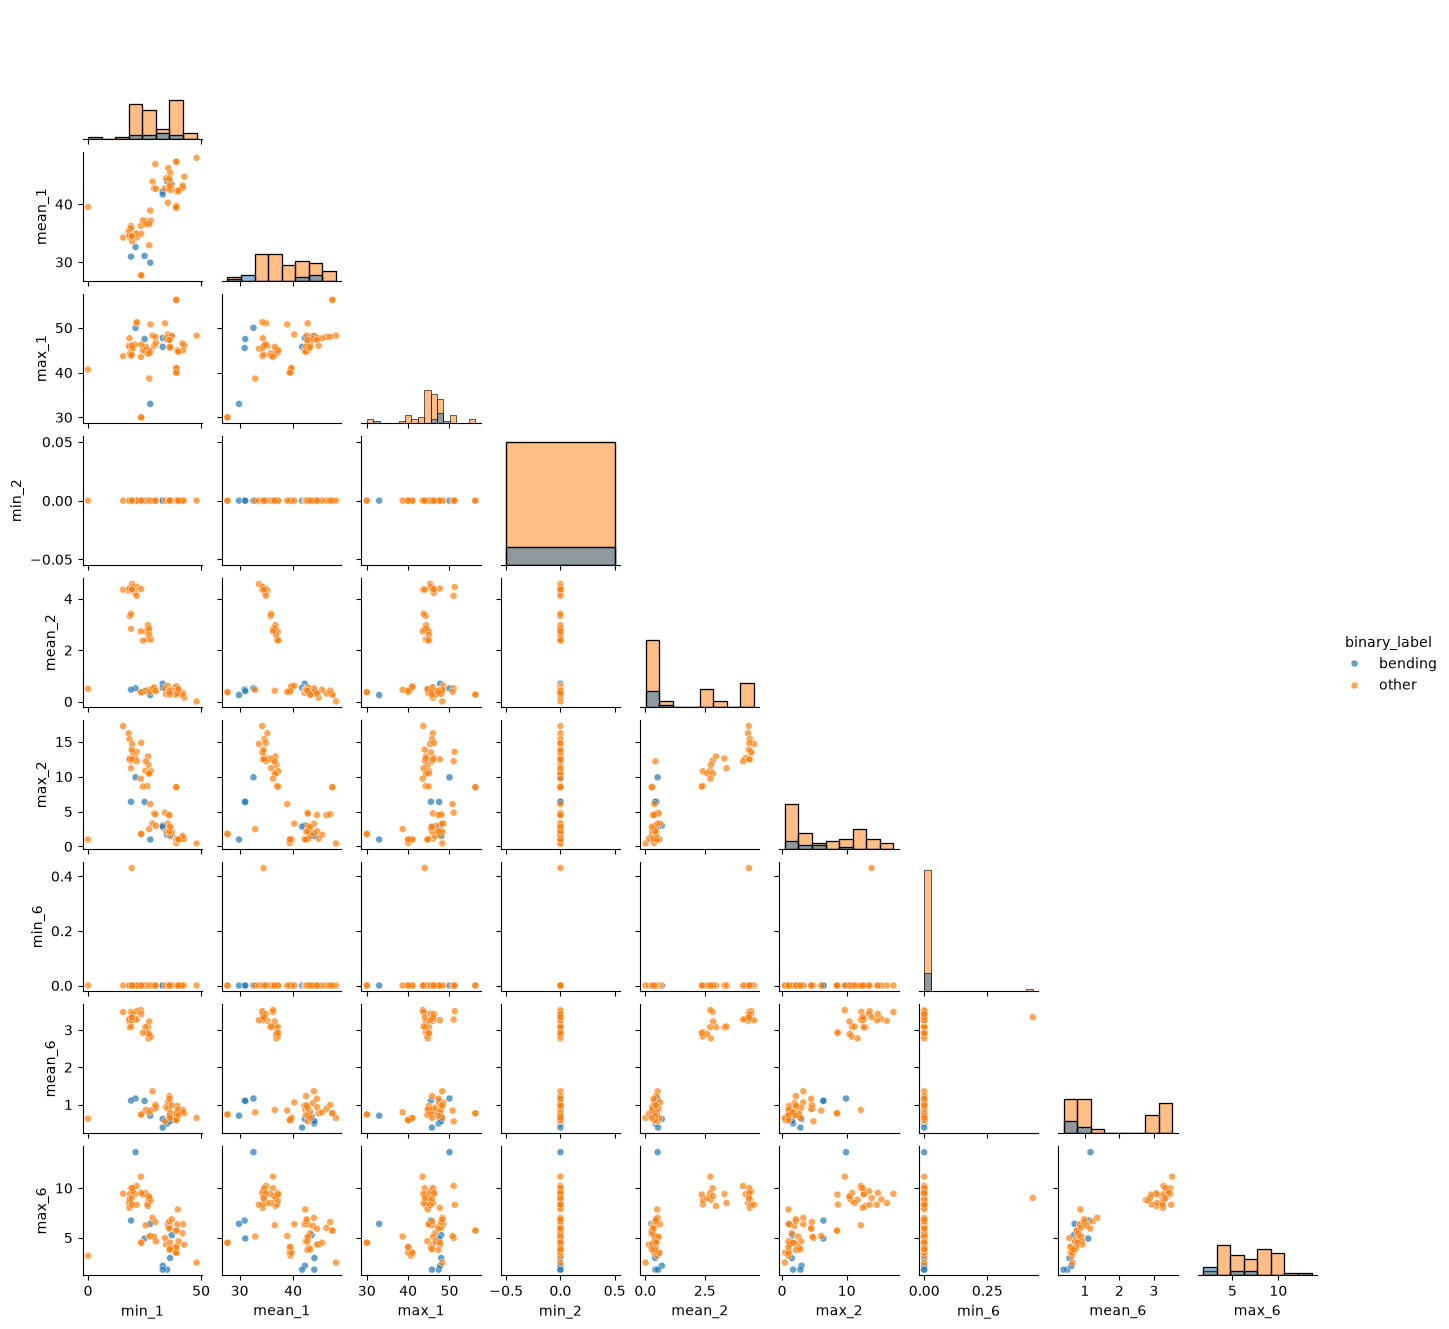

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_columns = [
    f"{stat}_{series_number}"
    for series_number in [1, 2, 6]
    for stat in ["min", "mean", "max"]
]

train_plot_data = feature_df.loc[
    feature_df["split"] == "train",
    plot_columns + ["binary_label"]
]

sns.pairplot(
    train_plot_data,
    vars=plot_columns,
    hue="binary_label",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 25},
    height=1.5
)

plt.show()

The scatterplots show some differences between bending and other activities. The minimum values for time series 2 and 6 are close to zero for most instances and do not clearly distinguish the two classes. The mean and maximum values for time series 2 and 6 show more separation, although some overlap remains. The features from time series 1 show less visible separation between the classes.

#### 2(a)(ii) Scatter Plots Using Two Subseries

I divided each time series in the training set into two approximately equal parts. For time series 1, 2, and 6, I extracted the minimum, mean, and maximum from each part. I then plotted the resulting features and used color to distinguish bending from other activities.

In [5]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data_dir = Path("data/AReM")

column_names = ["time"] + [f"series_{i}" for i in range(1, 7)]
rows = []

for file_path in sorted(data_dir.glob("**/*.csv")):
    folder_name = file_path.parent.name.lower()

    # Determine the dataset number from the filename
    match = re.search(r"dataset(\d+)", file_path.stem, flags=re.IGNORECASE)
    if match is None:
        continue
    dataset_number = int(match.group(1))

    # Apply the test-set rule from the assignment
    is_bending_folder = folder_name.startswith("bending")
    is_test_file = (
        dataset_number in (1, 2) if is_bending_folder
        else dataset_number in (1, 2, 3)
    )
    if is_test_file:
        continue

    activity = "bending" if is_bending_folder else "other"

    # Read the six sensor time series
    df = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        names=column_names,
        sep=r"\s*,\s*|\s+",
        engine="python",
        usecols=range(7)
    )

    row = {
        "file": str(file_path),
        "activity": activity,
        "binary_label": activity
    }

    # Split series 1, 2, and 6 into two approximately equal parts
    for series_number in (1, 2, 6):
        values = df[f"series_{series_number}"].dropna().to_numpy()
        parts = np.array_split(values, 2)

        for part_number, part_values in enumerate(parts, start=1):
            row[f"min_{series_number}_part{part_number}"] = np.min(part_values)
            row[f"mean_{series_number}_part{part_number}"] = np.mean(part_values)
            row[f"max_{series_number}_part{part_number}"] = np.max(part_values)

    rows.append(row)

split_feature_df = pd.DataFrame(rows)

print("Training instances:", len(split_feature_df))
print("Feature table shape:", split_feature_df.shape)
split_feature_df.head()

Training instances: 69
Feature table shape: (69, 21)


,file,activity,binary_label,min_1_part1,mean_1_part1,max_1_part1,min_1_part2,mean_1_part2,max_1_part2,min_2_part1,...,max_2_part1,min_2_part2,mean_2_part2,max_2_part2,min_6_part1,mean_6_part1,max_6_part1,min_6_part2,mean_6_part2,max_6_part2
0,data/AReM/bending1/dataset3.csv,bending,bending,36.50,44.057167,46.50,35.00,43.851833,47.40,0.0,...,1.50,0.0,0.471458,1.70,0.0,0.598250,1.79,0.0,0.388333,1.50
1,data/AReM/bending1/dataset4.csv,bending,bending,33.75,43.278875,47.75,33.00,41.080750,46.00,0.0,...,3.00,0.0,0.718792,2.86,0.0,0.640958,1.53,0.0,0.586083,2.18
2,data/AReM/bending1/dataset5.csv,bending,bending,33.00,41.621208,45.75,39.25,41.734917,43.67,0.0,...,2.83,0.0,0.448875,1.12,0.0,0.419083,1.79,0.0,0.347500,1.50
3,data/AReM/bending1/dataset6.csv,bending,bending,39.00,44.117042,48.00,37.00,42.792875,46.50,0.0,...,1.30,0.0,0.506125,1.58,0.0,0.815417,5.26,0.0,0.543875,4.06
4,data/AReM/bending1/dataset7.csv,bending,bending,36.67,43.486208,45.00,36.25,44.452042,48.00,0.0,...,1.30,0.0,0.447583,1.50,0.0,0.524875,2.28,0.0,0.585750,2.96


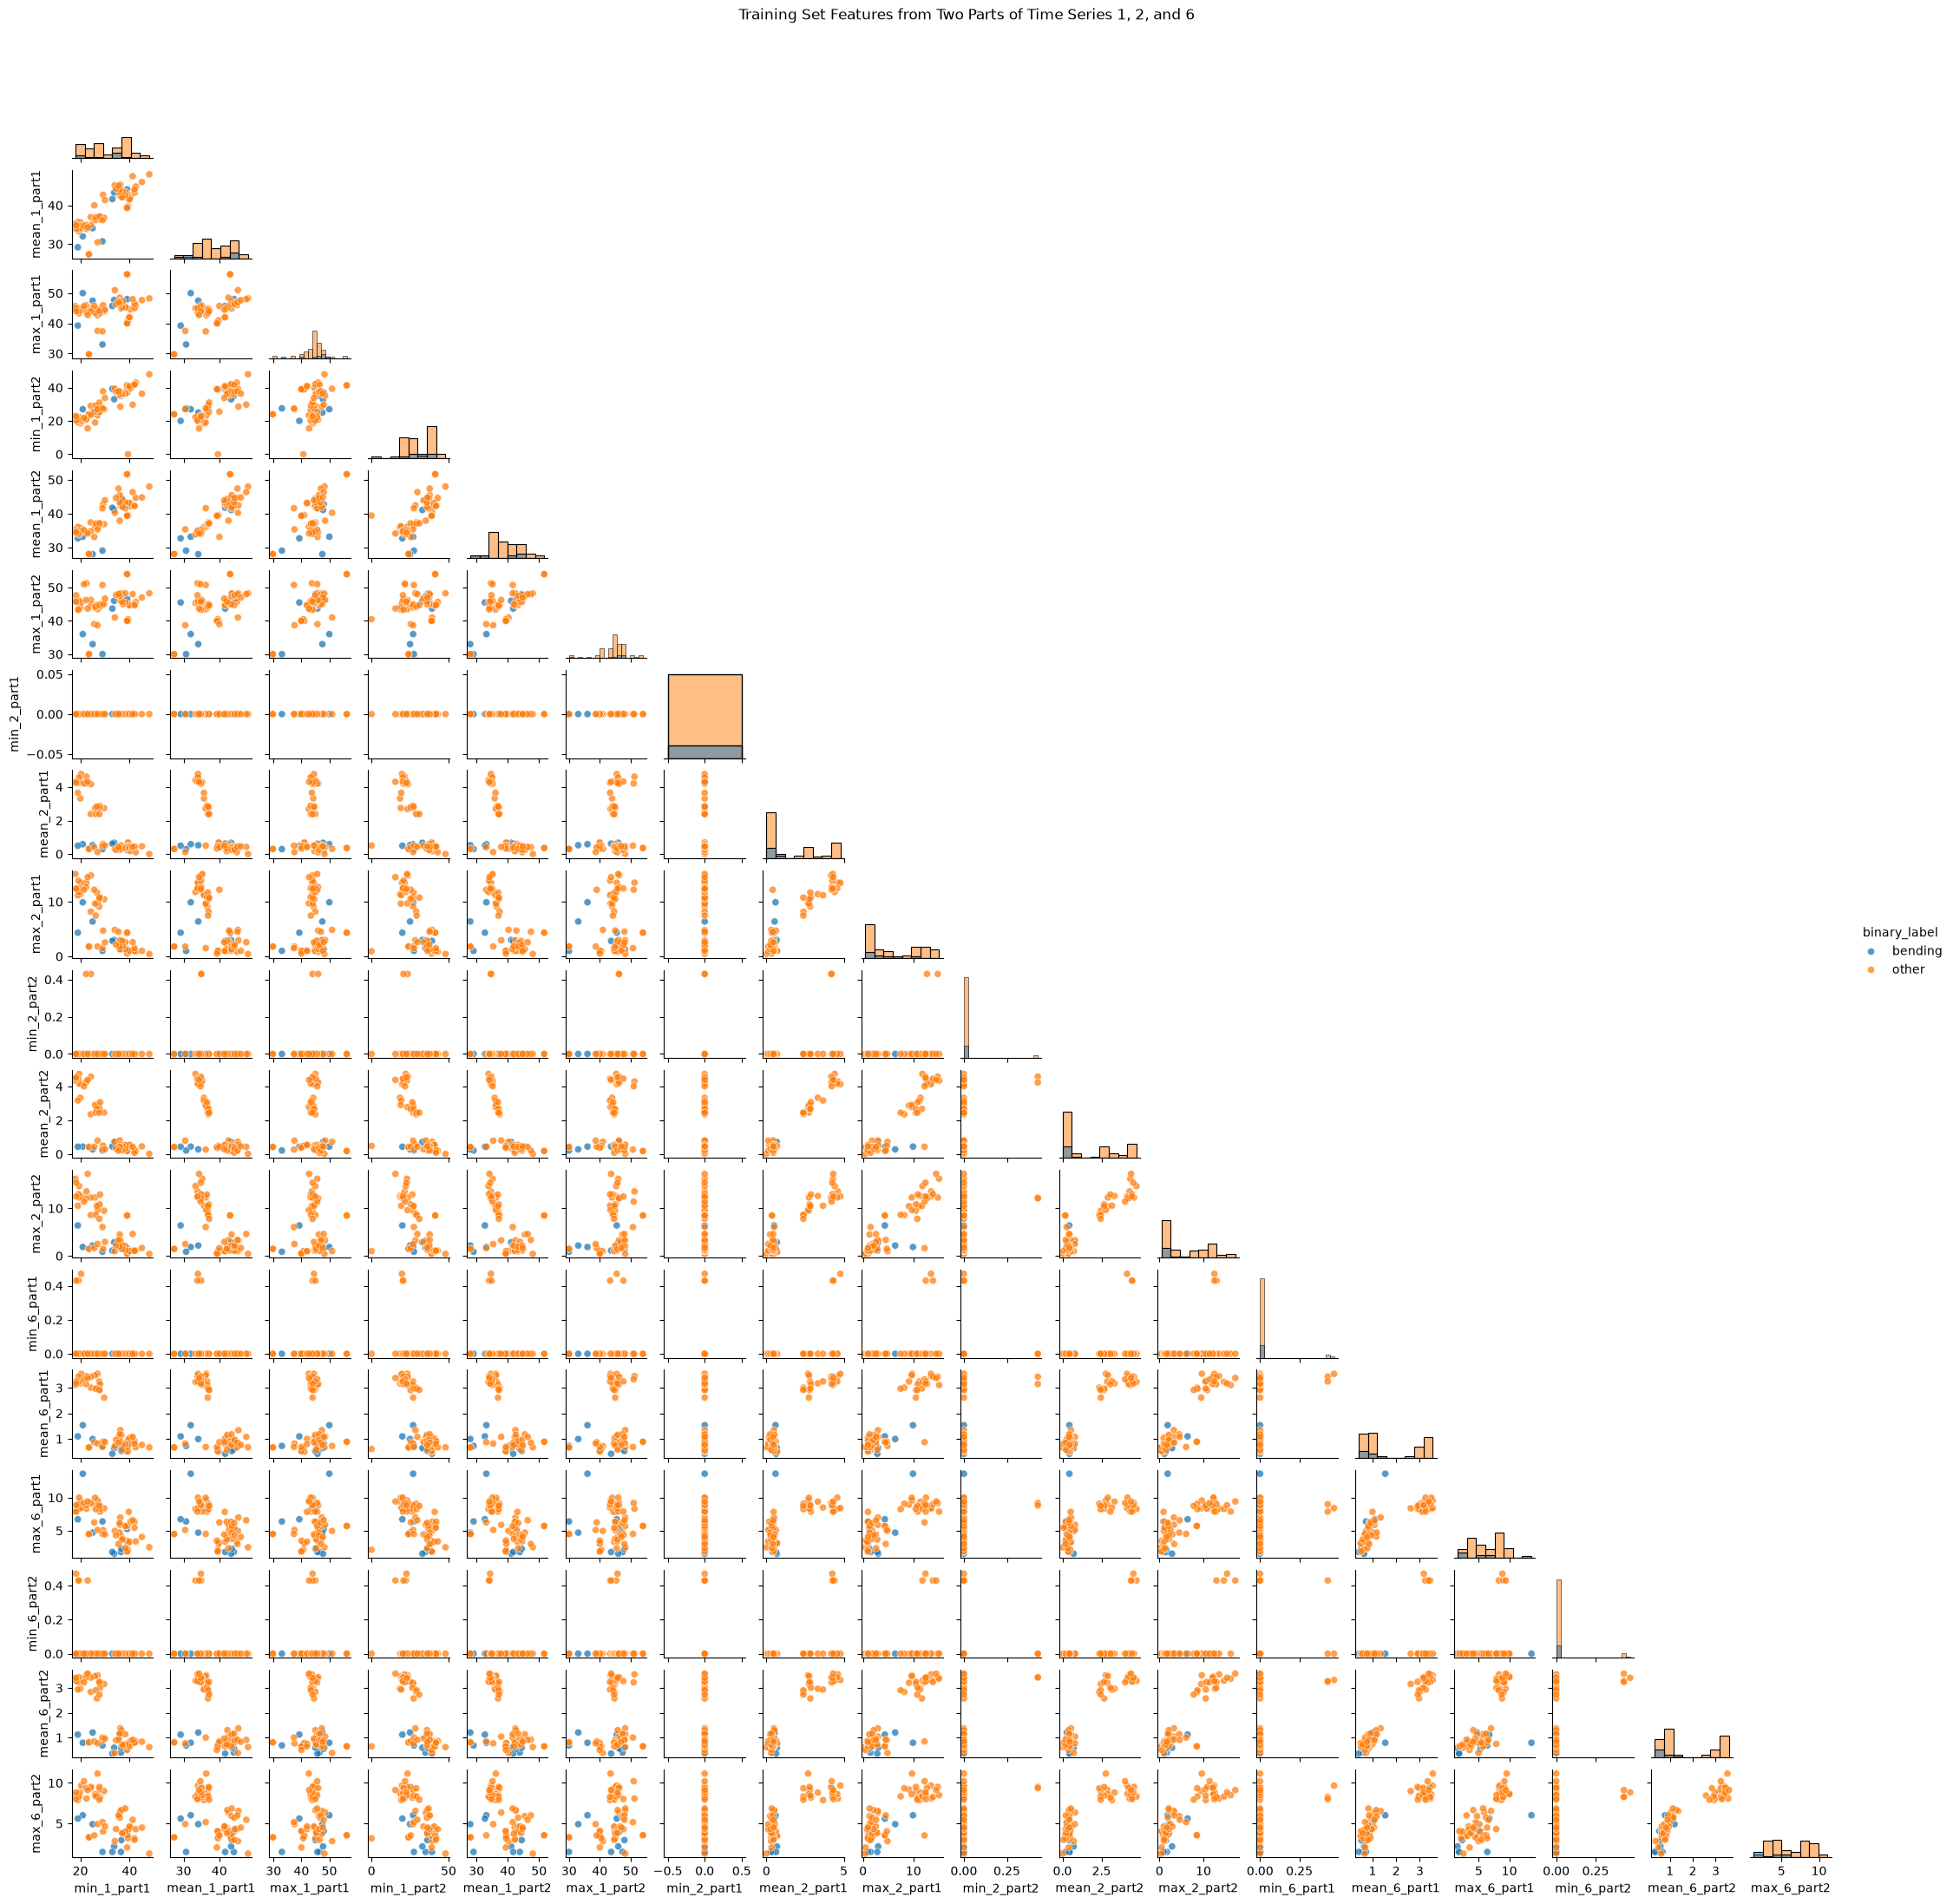

In [6]:
plot_columns = [
    f"{stat}_{series}_part{part}"
    for series in (1, 2, 6)
    for part in (1, 2)
    for stat in ("min", "mean", "max")
]

g = sns.pairplot(
    split_feature_df,
    vars=plot_columns,
    hue="binary_label",
    corner=True,
    diag_kind="hist",
    height=1.2,
    plot_kws={"alpha": 0.75, "s": 35}
)

g.fig.suptitle(
    "Training Set Features from Two Parts of Time Series 1, 2, and 6",
    y=1.02
)
plt.show()

Compared with 2(a)(i), splitting each time series provides features from two separate parts of each instance. The overall separation between bending and other activities appears broadly similar, although some features from individual parts show different patterns. The classes still overlap in some feature pairs, so the scatterplots do not show perfect separation.

#### 2(a)(iii) Logistic Regression with Recursive Feature Elimination

For each value of \(l\) from 1 to 20, I split the six time series into \(l\) approximately equal parts and calculated seven features for each part. I used RFE to select \(p\) features and compared the models with stratified 5-fold cross-validation.

Feature selection and scaling should be done separately within each fold. If I selected features once using the full training set before cross-validation, information from the validation folds could affect the selection and make the CV score too optimistic. I used a pipeline with StandardScaler and RFE so both steps were fitted on each fold's training portion before the model was evaluated on its validation portion.

In [7]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
import warnings

all_features_by_l = {}

# Read each training file once
training_data = []

for _, row in split_feature_df.iterrows():
    file_path = Path(row["file"])

    df = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        names=column_names,
        sep=r"\s*,\s*|\s+",
        engine="python",
        usecols=range(7)
    )

    series_values = {
        series_number: df[f"series_{series_number}"].dropna().to_numpy()
        for series_number in range(1, 7)
    }

    training_data.append((series_values, row["binary_label"]))

# Build one feature table for each l
for l in range(1, 21):
    rows = []

    for series_values, label in training_data:
        row = {"binary_label": label}

        for series_number in range(1, 7):
            parts = np.array_split(series_values[series_number], l)

            for part_number, part_values in enumerate(parts, start=1):
                row[f"series{series_number}_part{part_number}_min"] = np.min(part_values)
                row[f"series{series_number}_part{part_number}_max"] = np.max(part_values)
                row[f"series{series_number}_part{part_number}_mean"] = np.mean(part_values)
                row[f"series{series_number}_part{part_number}_median"] = np.median(part_values)
                row[f"series{series_number}_part{part_number}_std"] = np.std(part_values, ddof=1)
                row[f"series{series_number}_part{part_number}_q1"] = np.quantile(part_values, 0.25)
                row[f"series{series_number}_part{part_number}_q3"] = np.quantile(part_values, 0.75)

        rows.append(row)

    all_features_by_l[l] = pd.DataFrame(rows)

print("Number of training instances:", len(training_data))
print("Number of features when l=1:", all_features_by_l[1].shape[1] - 1)
print("Number of features when l=20:", all_features_by_l[20].shape[1] - 1)

Number of training instances: 69
Number of features when l=1: 42
Number of features when l=20: 840


In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Coarse candidate values for p
base_p_values = [1, 2, 5, 10, 20, 40, 80, 160, 320, 640]

cv_results = []

for l in range(1, 21):
    current_df = all_features_by_l[l]

    X = current_df.drop(columns="binary_label")
    y = (current_df["binary_label"] == "bending").astype(int)

    p_values = sorted({
        p for p in base_p_values if p <= X.shape[1]
    } | {X.shape[1]})

    base_model = LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=10000
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("rfe", RFE(estimator=base_model, step=0.5)),
        ("logistic", LogisticRegression(
            C=1e6,
            solver="liblinear",
            max_iter=10000
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"rfe__n_features_to_select": p_values},
        scoring="balanced_accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        search.fit(X, y)

    cv_results.append({
        "l": l,
        "best_p": search.best_params_["rfe__n_features_to_select"],
        "cv_balanced_accuracy": search.best_score_
    })

    print(
        f"l={l:2d}, best p={search.best_params_['rfe__n_features_to_select']:3d}, "
        f"CV balanced accuracy={search.best_score_:.3f}"
    )

cv_results_df = pd.DataFrame(cv_results).sort_values(
    "cv_balanced_accuracy",
    ascending=False
)

cv_results_df.head(10)

l= 1, best p= 20, CV balanced accuracy=0.992
l= 2, best p=  5, CV balanced accuracy=0.825
l= 3, best p=  1, CV balanced accuracy=0.950
l= 4, best p= 80, CV balanced accuracy=0.933
l= 5, best p= 10, CV balanced accuracy=0.833
l= 6, best p= 40, CV balanced accuracy=0.933
l= 7, best p= 10, CV balanced accuracy=0.925
l= 8, best p= 10, CV balanced accuracy=0.842
l= 9, best p=378, CV balanced accuracy=0.933
l=10, best p= 20, CV balanced accuracy=0.883
l=11, best p=160, CV balanced accuracy=0.883
l=12, best p= 40, CV balanced accuracy=0.883
l=13, best p=546, CV balanced accuracy=0.833
l=14, best p=320, CV balanced accuracy=0.833
l=15, best p=630, CV balanced accuracy=0.883
l=16, best p=320, CV balanced accuracy=0.875
l=17, best p= 80, CV balanced accuracy=0.875
l=18, best p=320, CV balanced accuracy=0.925
l=19, best p=320, CV balanced accuracy=0.875
l=20, best p=840, CV balanced accuracy=0.925


,l,best_p,cv_balanced_accuracy
0,1,20,0.991667
2,3,1,0.950000
8,9,378,0.933333
3,4,80,0.933333
5,6,40,0.933333
17,18,320,0.925000
19,20,840,0.925000
6,7,10,0.925000
9,10,20,0.883333
11,12,40,0.883333


In [9]:
best_result = cv_results_df.iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["best_p"])

print("Best l:", best_l)
print("Best p:", best_p)
print("Best 5-fold CV balanced accuracy:",
      round(best_result["cv_balanced_accuracy"], 3))

Best l: 1
Best p: 20
Best 5-fold CV balanced accuracy: 0.992


In [10]:
l = best_l
current_df = all_features_by_l[l]

X = current_df.drop(columns="binary_label")
y = (current_df["binary_label"] == "bending").astype(int)

base_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=10000
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(estimator=base_model, step=0.5)),
    ("logistic", LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=10000
    ))
])

refined_search = GridSearchCV(
    estimator=pipeline,
    param_grid={"rfe__n_features_to_select": list(range(15, 26))},
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True
)

refined_search.fit(X, y)

print("Refined best p:", refined_search.best_params_["rfe__n_features_to_select"])
print("Refined 5-fold CV balanced accuracy:", round(refined_search.best_score_, 3))

Refined best p: 15
Refined 5-fold CV balanced accuracy: 0.992


In [11]:
pd.DataFrame({
    "p": refined_search.cv_results_["param_rfe__n_features_to_select"].astype(int),
    "mean_cv_balanced_accuracy": refined_search.cv_results_["mean_test_score"]
}).sort_values(
    ["mean_cv_balanced_accuracy", "p"],
    ascending=[False, True]
)

,p,mean_cv_balanced_accuracy
0,15,0.991667
4,19,0.991667
5,20,0.991667
1,16,0.983333
2,17,0.983333
3,18,0.983333
6,21,0.983333
7,22,0.983333
8,23,0.983333
9,24,0.983333


The coarse search selected \(l=1\). In the refined search, \(p=15\), 19, and 20 tied for the highest 5-fold cross-validation balanced accuracy of 0.9917. I chose \(p=15\) because it uses the fewest features among the three, so the selected pair was \((l,p)=(1,15)\).

#### 2(a)(iv) Training Performance and Logistic Regression Parameters

I refit the selected model using the full training set with \(l=1\) and \(p=15\). I report its confusion matrix, ROC curve, AUC, coefficient estimates, and p-values.

In [12]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

# Use the selected model with the cross-validated value of l
l = best_l
current_df = all_features_by_l[l]

X_train = current_df.drop(columns="binary_label")
y_train = (current_df["binary_label"] == "bending").astype(int)

# Get the features selected by RFE
best_pipeline = refined_search.best_estimator_
selected_mask = best_pipeline.named_steps["rfe"].support_
selected_features = X_train.columns[selected_mask]

print("Number of selected features:", len(selected_features))
print("Selected features:")
print(list(selected_features))

# Scale the training features using the fitted scaler
X_scaled = pd.DataFrame(
    best_pipeline.named_steps["scaler"].transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Fit statsmodels logistic regression to obtain p-values
X_selected = sm.add_constant(X_scaled[selected_features], has_constant="add")
logit_result = sm.Logit(y_train, X_selected).fit(
    method="lbfgs",
    maxiter=1000,
    disp=False
)

coefficient_table = pd.DataFrame({
    "Coefficient (beta)": logit_result.params,
    "p-value": logit_result.pvalues
})

coefficient_table

Number of selected features: 15
Selected features:
['series1_part1_min', 'series1_part1_max', 'series1_part1_q3', 'series2_part1_max', 'series3_part1_min', 'series3_part1_max', 'series3_part1_std', 'series3_part1_q3', 'series4_part1_max', 'series4_part1_q1', 'series5_part1_min', 'series5_part1_max', 'series5_part1_mean', 'series6_part1_std', 'series6_part1_q1']


,Coefficient (beta),p-value
const,-13.434234,0.901318
series1_part1_min,-2.977943,0.973517
series1_part1_max,1.797724,0.995409
series1_part1_q3,-4.604745,0.985564
series2_part1_max,-2.397196,0.994203
series3_part1_min,-1.681375,0.997036
series3_part1_max,1.104018,0.998555
series3_part1_std,-0.950533,0.997969
series3_part1_q3,-1.782728,0.996022
series4_part1_max,3.195916,0.985940


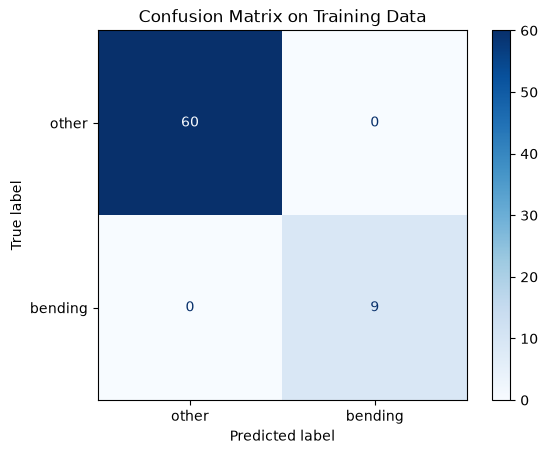

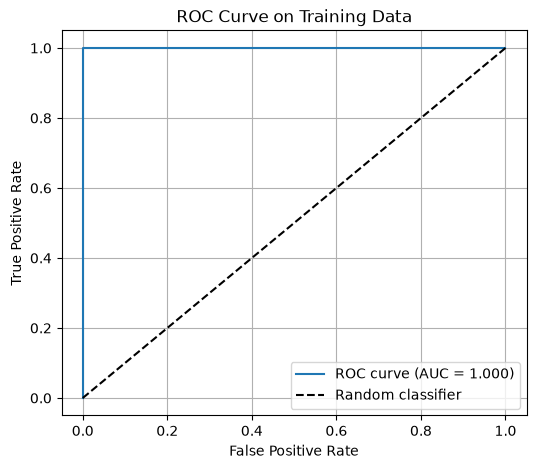

Training AUC: 1.0


In [13]:
# Predicted probabilities and class labels on the training set
y_probability = logit_result.predict(X_selected)
y_predicted = (y_probability >= 0.5).astype(int)

# Confusion matrix: rows are true labels, columns are predicted labels
cm = confusion_matrix(y_train, y_predicted, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["other", "bending"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix on Training Data")
plt.show()

# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_train, y_probability)
auc_value = roc_auc_score(y_train, y_probability)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Training Data")
plt.legend()
plt.grid(True)
plt.show()

print("Training AUC:", round(auc_value, 3))

In [14]:
print("Converged:", logit_result.mle_retvals.get("converged"))
print("Optimizer details:", logit_result.mle_retvals)

Converged: True
Optimizer details: {'fopt': np.float64(1.0214602422658996e-05), 'gopt': array([ 4.69079094e-06,  2.37208556e-06, -9.57827831e-07,  2.10110738e-06,
       -6.63220923e-07, -1.84855448e-06, -1.26630841e-06,  2.57874002e-06,
       -3.12388546e-07, -4.19331983e-06, -2.13799698e-06, -2.64894336e-06,
       -6.38766435e-07, -1.01524024e-06, -2.55502495e-06, -2.08622589e-06]), 'fcalls': 17, 'warnflag': 0, 'converged': True, 'iterations': 16}


The training results suggest that the classes may be linearly separable: all 69 training instances were classified correctly, and the training AUC was 1.000. Although the optimizer converged, coefficient estimates and p-values should be interpreted cautiously because class separation can make logistic regression estimates unstable. All coefficient p-values in this fit were greater than 0.05.

#### 2(a)(v) Test Set Evaluation

I evaluated the selected model on the test set. I used the same feature extraction procedure as for the training set and compared the test accuracy with the cross-validation accuracy.

In [15]:
test_rows = []
column_names = ["time"] + [f"series_{i}" for i in range(1, 7)]

for file_path in sorted(data_dir.glob("**/*.csv")):
    folder_name = file_path.parent.name.lower()

    match = re.search(r"dataset(\d+)", file_path.stem, flags=re.IGNORECASE)
    if match is None:
        continue

    dataset_number = int(match.group(1))
    is_bending_folder = folder_name.startswith("bending")

    is_test_file = (
        dataset_number in (1, 2) if is_bending_folder
        else dataset_number in (1, 2, 3)
    )

    if not is_test_file:
        continue

    activity = "bending" if is_bending_folder else "other"

    df = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        names=column_names,
        sep=r"\s*,\s*|\s+",
        engine="python",
        usecols=range(7)
    )

    row = {
        "file": str(file_path),
        "binary_label": activity
    }

    for series_number in range(1, 7):
        values = df[f"series_{series_number}"].dropna().to_numpy()
        parts = np.array_split(values, best_l)

        for part_number, part_values in enumerate(parts, start=1):
            row[f"series{series_number}_part{part_number}_min"] = np.min(part_values)
            row[f"series{series_number}_part{part_number}_max"] = np.max(part_values)
            row[f"series{series_number}_part{part_number}_mean"] = np.mean(part_values)
            row[f"series{series_number}_part{part_number}_median"] = np.median(part_values)
            row[f"series{series_number}_part{part_number}_std"] = np.std(
                part_values, ddof=1
            )
            row[f"series{series_number}_part{part_number}_q1"] = np.quantile(
                part_values, 0.25
            )
            row[f"series{series_number}_part{part_number}_q3"] = np.quantile(
                part_values, 0.75
            )

    test_rows.append(row)

test_feature_df = pd.DataFrame(test_rows)

X_test = test_feature_df.reindex(columns=X_train.columns)
y_test = (test_feature_df["binary_label"] == "bending").astype(int)

print("Number of test instances:", len(test_feature_df))
print("Test class counts:")
print(test_feature_df["binary_label"].value_counts())

Number of test instances: 19
Test class counts:
binary_label
other      15
bending     4
Name: count, dtype: int64


Test accuracy: 1.0
Test balanced accuracy: 1.0


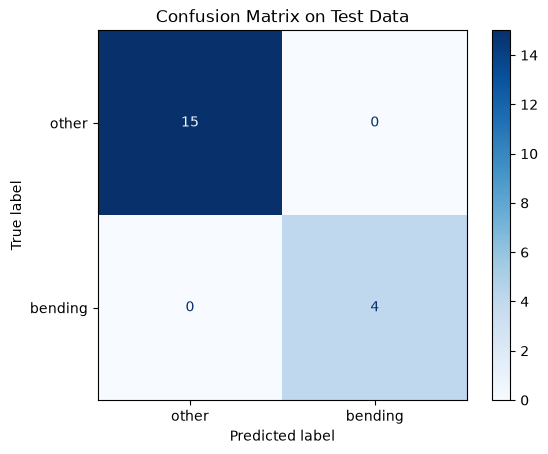

In [16]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import cross_val_score

final_model = refined_search.best_estimator_

y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

test_accuracy = accuracy_score(y_test, y_test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)

print("Test accuracy:", round(test_accuracy, 3))
print("Test balanced accuracy:", round(test_balanced_accuracy, 3))

test_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["other", "bending"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix on Test Data")
plt.show()

In [17]:
cv_accuracy_scores = cross_val_score(
    final_model, X_train, y_train, cv=cv, scoring="accuracy"
)

cv_balanced_accuracy_scores = cross_val_score(
    final_model, X_train, y_train, cv=cv, scoring="balanced_accuracy"
)

print("5-fold CV accuracy:", round(cv_accuracy_scores.mean(), 3))
print(
    "5-fold CV balanced accuracy:",
    round(cv_balanced_accuracy_scores.mean(), 3)
)
print("Test accuracy:", round(test_accuracy, 3))
print("Test balanced accuracy:", round(test_balanced_accuracy, 3))

5-fold CV accuracy: 0.986
5-fold CV balanced accuracy: 0.992
Test accuracy: 1.0
Test balanced accuracy: 1.0


The model correctly classified all 19 test instances: 15 other instances and 4 bending instances. The test accuracy and balanced accuracy were both 1.000. The 5-fold cross-validation accuracy was 0.986, and the cross-validation balanced accuracy was 0.992. The test accuracy was slightly higher than the cross-validation accuracy. Since the test set contains only 19 instances, these results should be interpreted with that sample size in mind.

#### 2(a)(vi) Class Separation

The training and test results suggest that bending and other activities are well separated by the selected features in this dataset. The model correctly classified every training and test instance. However, the training and test sets are small, so these results do not guarantee perfect classification on new data. The high coefficient p-values also mean that the individual coefficients should be interpreted cautiously. This degree of separation can make logistic regression coefficient estimates unstable, so the coefficients and p-values should be interpreted cautiously.

#### 2(a)(vii) Logistic Regression with Case-Control Sampling

The training set contains 60 other instances and 9 bending instances, so the classes are imbalanced. I created a balanced case-control training sample by resampling bending instances with replacement. I adjusted the fitted model's intercept to account for the difference between the sampled class proportion and the original training-set proportion. I evaluated the adjusted model on the test set.

In [18]:
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

# Reuse the scaler and RFE-selected features from the l=1, p=15 model
best_pipeline = refined_search.best_estimator_
scaler = best_pipeline.named_steps["scaler"]
selected_mask = best_pipeline.named_steps["rfe"].support_
selected_features = X_train.columns[selected_mask]

X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

X_train_selected = X_train_scaled[selected_features]
X_test_selected = X_test_scaled[selected_features]

# Oversample the bending class to match the number of other instances
y_train_array = y_train.to_numpy()
negative_indices = np.flatnonzero(y_train_array == 0)
positive_indices = np.flatnonzero(y_train_array == 1)

rng = np.random.default_rng(42)
resampled_positive_indices = rng.choice(
    positive_indices,
    size=len(negative_indices),
    replace=True
)

X_case_control = np.vstack([
    X_train_selected.iloc[negative_indices].to_numpy(),
    X_train_selected.iloc[resampled_positive_indices].to_numpy()
])
y_case_control = np.concatenate([
    np.zeros(len(negative_indices), dtype=int),
    np.ones(len(negative_indices), dtype=int)
])

# Shuffle the balanced sample
shuffle_indices = rng.permutation(len(y_case_control))
X_case_control = X_case_control[shuffle_indices]
y_case_control = y_case_control[shuffle_indices]

case_control_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=10000
)
case_control_model.fit(X_case_control, y_case_control)

print("Balanced case-control sample counts:")
print(pd.Series(y_case_control).value_counts().sort_index())

Balanced case-control sample counts:
0    60
1    60
Name: count, dtype: int64


In [19]:
training_prevalence = y_train.mean()
sample_prevalence = y_case_control.mean()

intercept_adjustment = (
    logit(training_prevalence) - logit(sample_prevalence)
)

adjusted_intercept = (
    case_control_model.intercept_[0] + intercept_adjustment
)

print("Training bending prevalence:", round(training_prevalence, 3))
print("Case-control sample prevalence:", round(sample_prevalence, 3))
print("Intercept adjustment:", round(intercept_adjustment, 3))
print("Adjusted intercept:", round(adjusted_intercept, 3))

# The intercept correction shifts the model's decision scores
test_scores_adjusted = (
    case_control_model.decision_function(X_test_selected.to_numpy())
    + intercept_adjustment
)
test_probabilities_adjusted = expit(test_scores_adjusted)
test_predictions_case_control = (
    test_probabilities_adjusted >= 0.5
).astype(int)

Training bending prevalence: 0.13
Case-control sample prevalence: 0.5
Intercept adjustment: -1.897
Adjusted intercept: -13.184


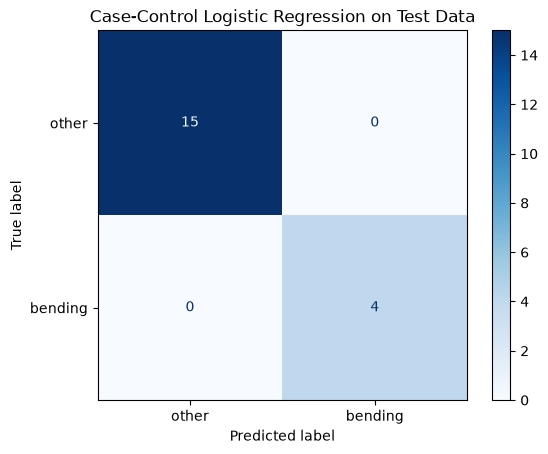

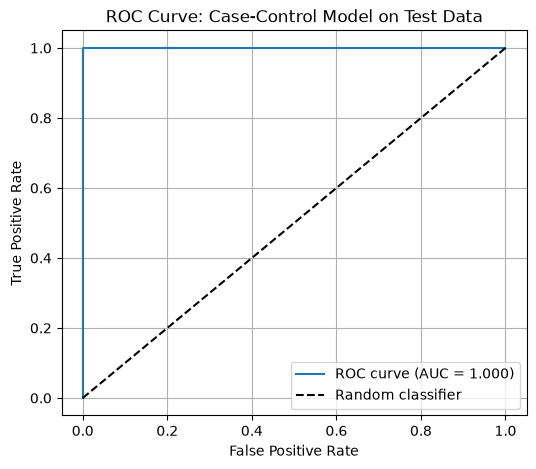

Case-control test AUC: 1.0


In [20]:
case_control_cm = confusion_matrix(
    y_test,
    test_predictions_case_control,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=case_control_cm,
    display_labels=["other", "bending"]
).plot(cmap="Blues", values_format="d")

plt.title("Case-Control Logistic Regression on Test Data")
plt.show()

fpr_cc, tpr_cc, _ = roc_curve(y_test, test_probabilities_adjusted)
auc_cc = roc_auc_score(y_test, test_probabilities_adjusted)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cc, tpr_cc, label=f"ROC curve (AUC = {auc_cc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Case-Control Model on Test Data")
plt.legend()
plt.grid(True)
plt.show()

print("Case-control test AUC:", round(auc_cc, 3))

The training set was imbalanced, with 60 other instances and 9 bending instances. After creating a balanced case-control sample, I adjusted the intercept by -1.897 to account for the original training-set prevalence. On the test set, the model correctly classified all 15 other instances and all 4 bending instances, with an AUC of 1.000.

#### 2(b)(i) L1-Penalized Logistic Regression

I used L1-penalized logistic regression and stratified 5-fold cross-validation to select \(l\) and \(C\). The features were standardized within each training fold. L1 regularization can set some coefficients to zero, which performs feature selection. A smaller \(C\) corresponds to stronger regularization.

In [21]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

# 5-fold 
cv_l1 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

l1_results = []
l1_searches = {}


for l in range(1, 21):
    feature_df = all_features_by_l[l]

    X_l = (
        feature_df
        .select_dtypes(include="number")
        .drop(columns=["binary_label"], errors="ignore")
        .reset_index(drop=True)
    )

    y_l = split_feature_df["binary_label"].reset_index(drop=True)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="liblinear",
            l1_ratio=1.0,
            max_iter=10000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"logistic__C": C_values},
        scoring="balanced_accuracy",
        cv=cv_l1,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_l, y_l)
    l1_searches[l] = search

    l1_results.append({
        "l": l,
        "best_C": search.best_params_["logistic__C"],
        "cv_balanced_accuracy": search.best_score_
    })

l1_results_df = (
    pd.DataFrame(l1_results)
    .sort_values("cv_balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

display(l1_results_df)

best_l1 = l1_results_df.iloc[0]
best_l = int(best_l1["l"])
best_C = float(best_l1["best_C"])
best_score = float(best_l1["cv_balanced_accuracy"])

best_l1_model = l1_searches[best_l].best_estimator_

print("Best l:", best_l)
print("Best C:", best_C)
print("Best 5-fold CV balanced accuracy:", best_score)

,l,best_C,cv_balanced_accuracy
0,1,10000,0.991667
1,10,100,0.941667
2,12,1,0.941667
3,2,10,0.941667
4,20,100,0.941667
5,6,100,0.933333
6,9,10000,0.933333
7,4,10000,0.933333
8,3,1,0.891667
9,13,1,0.891667


Best l: 1
Best C: 10000.0
Best 5-fold CV balanced accuracy: 0.9916666666666666


For the L1-penalized logistic regression, I used 5-fold stratified cross-validation to select both the number of time segments \(l\) and the regularization parameter \(C\). Among the values tested, the best result was obtained with \(l=1\) and \(C=10000\), with a mean cross-validation balanced accuracy of 0.9917.

#### 2(b)(ii) Comparison of L1-Penalized Logistic Regression and P-Value-Based Feature Selection

The p-value-based feature selection and the L1-penalized logistic regression achieved the same best 5-fold cross-validation balanced accuracy, 0.9917. Both selected \(l=1\), so neither method performed better based on these results.

The L1-penalized approach was easier to implement because the model performs feature selection through regularization while fitting. The p-value-based approach required additional steps to fit the models, evaluate feature significance, select features, and refit the classifier.

#### 2(c)(i) Multiclass Classification Using L1-Penalized Logistic Regression

In [22]:
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Extract the seven activity labels from the training file paths
y_multi = (
    split_feature_df["file"]
    .apply(lambda file_path: Path(str(file_path)).parent.name)
    .reset_index(drop=True)
)

print("Training activity counts:")
print(y_multi.value_counts().sort_index())

C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

# Set up 5-fold stratified cross-validation
cv_multi = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

multi_results = []
multi_searches = {}

# Search for the best C for each value of l
for l in range(1, 21):
    feature_df = all_features_by_l[l]

    # Keep numeric features and remove the binary label column
    X_l = (
        feature_df
        .select_dtypes(include="number")
        .drop(columns=["binary_label"], errors="ignore")
        .reset_index(drop=True)
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="saga",
            l1_ratio=1.0,
            max_iter=20000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"logistic__C": C_values},
        scoring="balanced_accuracy",
        cv=cv_multi,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_l, y_multi)
    multi_searches[l] = search

    multi_results.append({
        "l": l,
        "best_C": search.best_params_["logistic__C"],
        "cv_balanced_accuracy": search.best_score_
    })

multi_results_df = (
    pd.DataFrame(multi_results)
    .sort_values("cv_balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

display(multi_results_df)

best_multi_row = multi_results_df.iloc[0]
best_multi_l = int(best_multi_row["l"])
best_multi_C = float(best_multi_row["best_C"])
best_multi_score = float(best_multi_row["cv_balanced_accuracy"])
best_multi_model = multi_searches[best_multi_l].best_estimator_

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print("Best 5-fold CV balanced accuracy:", best_multi_score)
print("Model classes:", best_multi_model.classes_)

Training activity counts:
file
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64


/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,l,best_C,cv_balanced_accuracy
0,2,10,0.880952
1,1,10,0.879365
2,4,10,0.850794
3,5,100,0.841270
4,18,100,0.841270
5,8,1000,0.826984
6,6,1000,0.822222
7,3,100,0.807937
8,15,10000,0.806349
9,10,100,0.806349


Best l: 2
Best C: 10.0
Best 5-fold CV balanced accuracy: 0.880952380952381
Model classes: ['bending1' 'bending2' 'cycling' 'lying' 'sitting' 'standing' 'walking']


The 5-fold cross-validation selected l = 2 and C = 10 for the L1-penalized logistic regression model. The best mean balanced accuracy was about 0.881. I used these selected parameters to fit the model before evaluating it on the test set.

Number of test instances: 19
Test activity counts:
activity
bending1    2
bending2    2
cycling     3
lying       3
sitting     3
standing    3
walking     3
Name: count, dtype: int64
Test accuracy: 0.8421052631578947
Test error: 0.1578947368421053
              precision    recall  f1-score   support

    bending1       0.67      1.00      0.80         2
    bending2       1.00      0.50      0.67         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.50      0.33      0.40         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.84        19
   macro avg       0.85      0.83      0.82        19
weighted avg       0.85      0.84      0.83        19



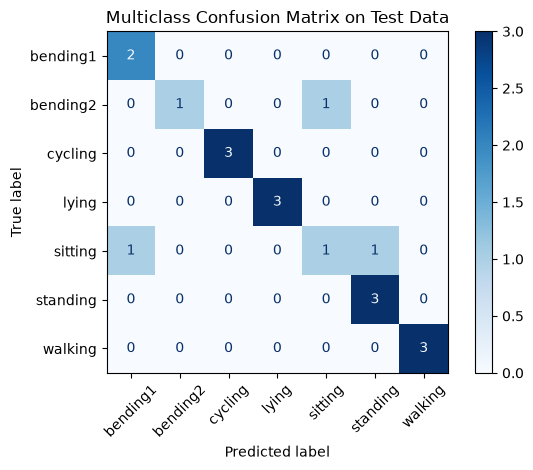

Macro-average one-vs-rest ROC AUC: 0.9497549019607844


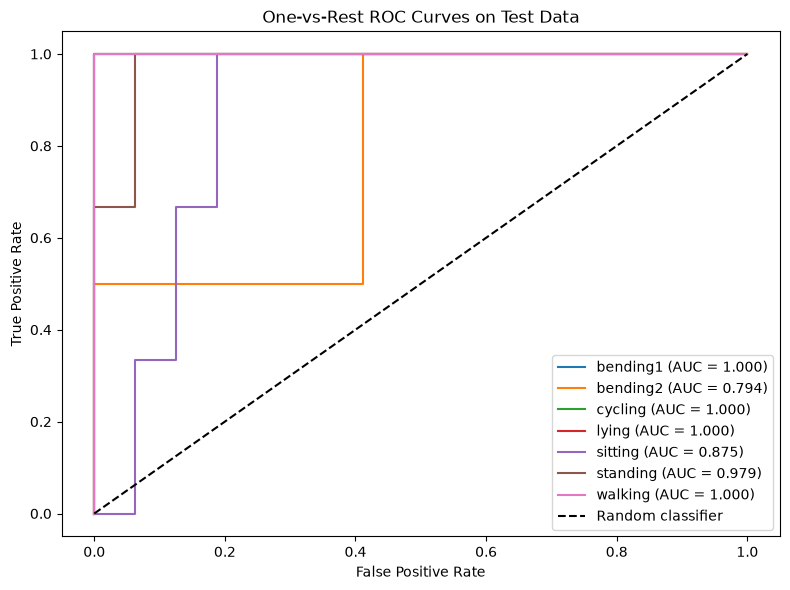

In [23]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Set the relative path to the AReM data folder
data_dir = Path("data/AReM")

test_records = []

# Select the test files specified in the assignment
for file_path in sorted(data_dir.rglob("dataset*.csv")):
    activity = file_path.parent.name
    match = re.search(r"dataset(\d+)", file_path.stem, re.IGNORECASE)

    if match is None:
        continue

    dataset_number = int(match.group(1))

    if activity in {"bending1", "bending2"}:
        is_test_file = dataset_number in {1, 2}
    else:
        is_test_file = dataset_number in {1, 2, 3}

    if not is_test_file:
        continue

    # Read the six sensor time series
    raw_df = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        usecols=range(7)
    )

    raw_df = raw_df.apply(pd.to_numeric, errors="coerce").dropna()
    sensor_data = raw_df.iloc[:, 1:7]

    # Extract time-domain features using the selected value of l
    feature_row = {}

    for series_index in range(6):
        segments = np.array_split(
            sensor_data.iloc[:, series_index].to_numpy(),
            best_multi_l
        )

        for part_index, segment in enumerate(segments, start=1):
            values = pd.Series(segment)

            feature_row[f"series{series_index + 1}_part{part_index}_min"] = values.min()
            feature_row[f"series{series_index + 1}_part{part_index}_max"] = values.max()
            feature_row[f"series{series_index + 1}_part{part_index}_mean"] = values.mean()
            feature_row[f"series{series_index + 1}_part{part_index}_median"] = values.median()
            feature_row[f"series{series_index + 1}_part{part_index}_std"] = values.std()
            feature_row[f"series{series_index + 1}_part{part_index}_q1"] = values.quantile(0.25)
            feature_row[f"series{series_index + 1}_part{part_index}_q3"] = values.quantile(0.75)

    test_records.append({
        "file": str(file_path),
        "activity": activity,
        **feature_row
    })

test_feature_df = pd.DataFrame(test_records)

# Match the test feature columns to the training feature columns
train_feature_df = all_features_by_l[best_multi_l]
train_feature_cols = (
    train_feature_df
    .select_dtypes(include="number")
    .drop(columns=["binary_label"], errors="ignore")
    .columns
)

X_test_multi = test_feature_df.reindex(columns=train_feature_cols)
y_test_multi = test_feature_df["activity"]

print("Number of test instances:", len(y_test_multi))
print("Test activity counts:")
print(y_test_multi.value_counts().sort_index())

# Predict the test labels
y_test_pred = best_multi_model.predict(X_test_multi)

# Calculate test accuracy and test error
test_accuracy = accuracy_score(y_test_multi, y_test_pred)
test_error = 1 - test_accuracy

print("Test accuracy:", test_accuracy)
print("Test error:", test_error)
print(classification_report(y_test_multi, y_test_pred, zero_division=0))

# Plot the multiclass confusion matrix
class_labels = best_multi_model.classes_
cm = confusion_matrix(y_test_multi, y_test_pred, labels=class_labels)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
).plot(xticks_rotation=45, cmap="Blues")

plt.title("Multiclass Confusion Matrix on Test Data")
plt.tight_layout()
plt.show()

# Calculate the macro-average one-vs-rest ROC AUC
test_probabilities = best_multi_model.predict_proba(X_test_multi)

macro_ovr_auc = roc_auc_score(
    y_test_multi,
    test_probabilities,
    multi_class="ovr",
    average="macro"
)

print("Macro-average one-vs-rest ROC AUC:", macro_ovr_auc)

# Plot one-vs-rest ROC curves for each activity
y_test_binary = label_binarize(y_test_multi, classes=class_labels)

plt.figure(figsize=(8, 6))

for class_index, class_name in enumerate(class_labels):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, class_index],
        test_probabilities[:, class_index]
    )
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {class_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves on Test Data")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The model correctly classified 16 of the 19 test instances. Its test accuracy was about 0.842, and its test error was about 0.158. The macro-average one-vs-rest ROC AUC was about 0.950. The confusion matrix shows that three instances were misclassified: one bending2 instance was predicted as sitting, and two sitting instances were predicted as bending1 and standing. Overall, the model performed well on the test set, although it confused a few activities.

#### 2(c)(ii) Multiclass Classification Using Naive Bayes

In [24]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.base import clone
import pandas as pd
from pathlib import Path

# Use the activity folder names as the multiclass target labels
y_multi = (
    split_feature_df["file"]
    .apply(lambda file_path: Path(str(file_path)).parent.name)
    .reset_index(drop=True)
)

# Set up 5-fold stratified cross-validation
cv_nb = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Scale features to non-negative values for MultinomialNB
nb_models = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": Pipeline([
        ("scaler", MinMaxScaler()),
        ("nb", MultinomialNB())
    ])
}

nb_results = []
nb_features_by_l = {}

# Compare both classifiers for each value of l
for l in range(1, 21):
    feature_df = all_features_by_l[l]

    X_l = (
        feature_df
        .select_dtypes(include="number")
        .drop(columns=["binary_label"], errors="ignore")
        .reset_index(drop=True)
    )

    nb_features_by_l[l] = X_l

    for model_name, model in nb_models.items():
        scores = cross_val_score(
            model,
            X_l,
            y_multi,
            cv=cv_nb,
            scoring="balanced_accuracy"
        )

        nb_results.append({
            "model": model_name,
            "l": l,
            "cv_balanced_accuracy": scores.mean()
        })

nb_results_df = (
    pd.DataFrame(nb_results)
    .sort_values("cv_balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

display(nb_results_df)

# Find the best value of l for each classifier
best_nb_results = (
    nb_results_df
    .sort_values("cv_balanced_accuracy", ascending=False)
    .groupby("model", as_index=False)
    .first()
)

display(best_nb_results)

# Fit each selected model on the full training set
best_nb_models = {}

for _, row in best_nb_results.iterrows():
    model_name = row["model"]
    best_l_nb = int(row["l"])

    fitted_model = clone(nb_models[model_name])
    fitted_model.fit(nb_features_by_l[best_l_nb], y_multi)

    best_nb_models[model_name] = {
        "l": best_l_nb,
        "model": fitted_model,
        "cv_balanced_accuracy": row["cv_balanced_accuracy"]
    }

print("Training activity counts:")
print(y_multi.value_counts().sort_index())

/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,model,l,cv_balanced_accuracy
0,GaussianNB,1,0.819048
1,GaussianNB,2,0.742857
2,MultinomialNB,2,0.714286
3,MultinomialNB,3,0.690476
4,MultinomialNB,8,0.685714
5,MultinomialNB,5,0.685714
6,MultinomialNB,1,0.676190
7,MultinomialNB,4,0.676190
8,MultinomialNB,6,0.666667
9,MultinomialNB,9,0.666667


,model,l,cv_balanced_accuracy
0,GaussianNB,1,0.819048
1,MultinomialNB,2,0.714286


Training activity counts:
file
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64


Number of test files: 19

GaussianNB
Best l: 1
5-fold CV balanced accuracy: 0.819047619047619
Test accuracy: 0.8947368421052632
Test error: 0.10526315789473684
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      0.67      0.80         3
     sitting       0.60      1.00      0.75         3
    standing       1.00      0.67      0.80         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.89        19
   macro avg       0.94      0.90      0.91        19
weighted avg       0.94      0.89      0.90        19



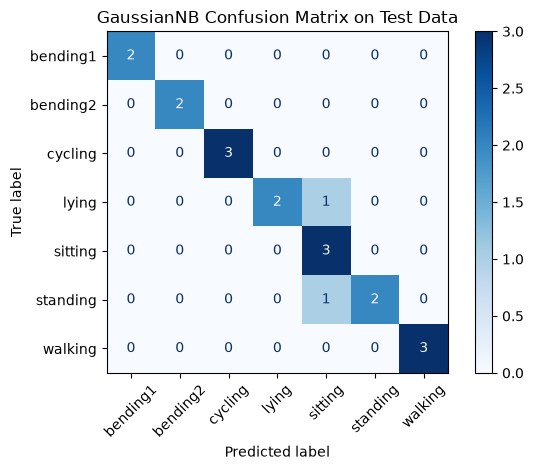

Macro-average one-vs-rest ROC AUC: 0.9642857142857143


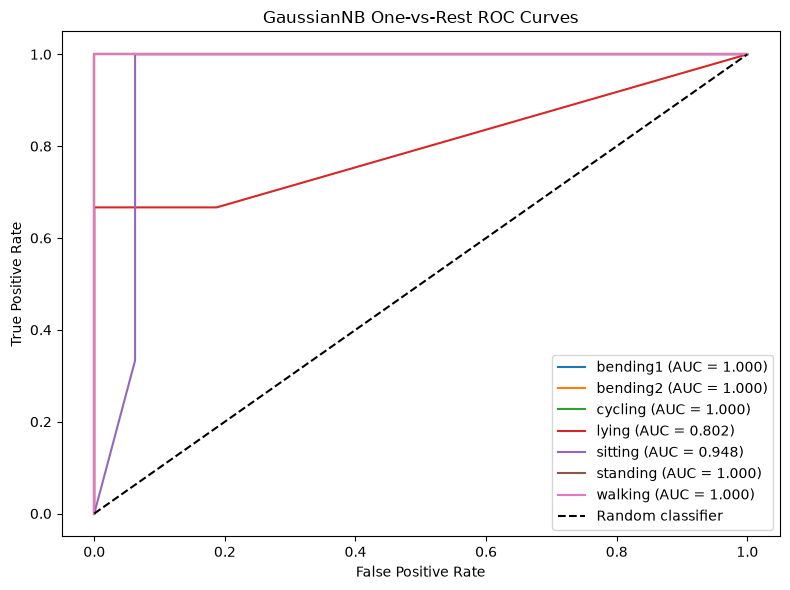


MultinomialNB
Best l: 2
5-fold CV balanced accuracy: 0.7142857142857143
Test accuracy: 0.7894736842105263
Test error: 0.21052631578947367
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      0.50      0.67         2
     cycling       0.75      1.00      0.86         3
       lying       1.00      0.67      0.80         3
     sitting       0.50      0.67      0.57         3
    standing       0.67      0.67      0.67         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.79        19
   macro avg       0.85      0.79      0.79        19
weighted avg       0.83      0.79      0.79        19



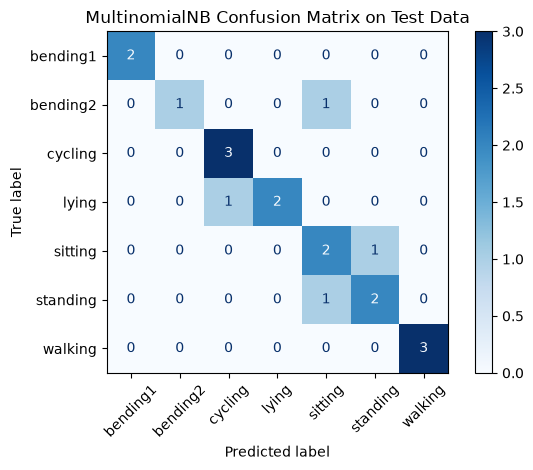

Macro-average one-vs-rest ROC AUC: 0.9672619047619048


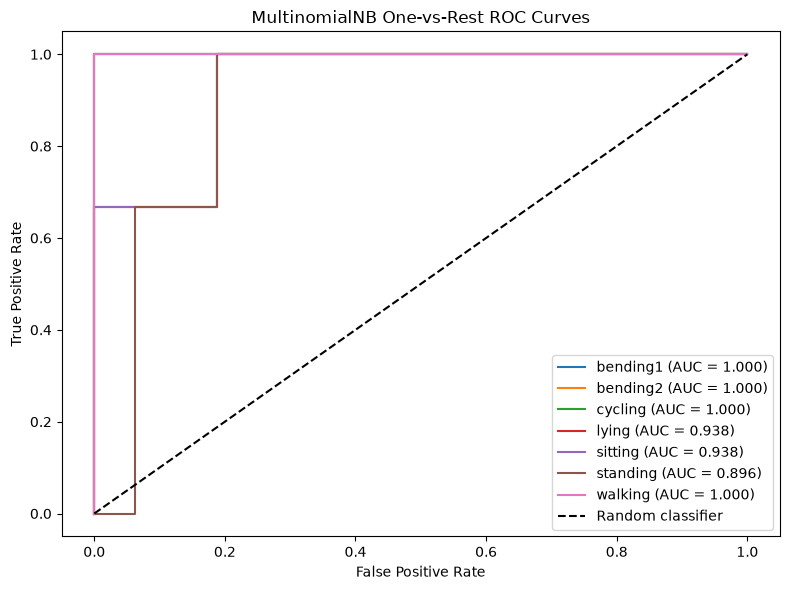

In [25]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Set the relative path to the AReM data folder
data_dir = Path("data/AReM")
column_names = ["time"] + [f"series_{i}" for i in range(1, 7)]

# Identify the test files specified in the assignment
test_files = []

for file_path in sorted(data_dir.glob("**/*.csv")):
    activity = file_path.parent.name.lower()
    match = re.search(r"dataset(\d+)", file_path.stem, flags=re.IGNORECASE)

    if match is None:
        continue

    dataset_number = int(match.group(1))

    if activity in {"bending1", "bending2"}:
        is_test_file = dataset_number in {1, 2}
    else:
        is_test_file = dataset_number in {1, 2, 3}

    if is_test_file:
        test_files.append((file_path, activity))

print("Number of test files:", len(test_files))

# Build test features for a selected value of l
def build_test_features(l):
    test_rows = []

    for file_path, activity in test_files:
        df = pd.read_csv(
            file_path,
            comment="#",
            header=None,
            names=column_names,
            sep=r"\s*,\s*|\s+",
            engine="python",
            usecols=range(7)
        )

        row = {
            "file": str(file_path),
            "activity": activity
        }

        for series_number in range(1, 7):
            values = df[f"series_{series_number}"].dropna().to_numpy()
            parts = np.array_split(values, l)

            for part_number, part_values in enumerate(parts, start=1):
                row[f"series{series_number}_part{part_number}_min"] = np.min(part_values)
                row[f"series{series_number}_part{part_number}_max"] = np.max(part_values)
                row[f"series{series_number}_part{part_number}_mean"] = np.mean(part_values)
                row[f"series{series_number}_part{part_number}_median"] = np.median(part_values)
                row[f"series{series_number}_part{part_number}_std"] = np.std(
                    part_values, ddof=1
                )
                row[f"series{series_number}_part{part_number}_q1"] = np.quantile(
                    part_values, 0.25
                )
                row[f"series{series_number}_part{part_number}_q3"] = np.quantile(
                    part_values, 0.75
                )

        test_rows.append(row)

    return pd.DataFrame(test_rows)

# Evaluate each Naive Bayes model on the test set
for model_name, model_info in best_nb_models.items():
    best_l_nb = model_info["l"]
    model = model_info["model"]

    test_feature_df_nb = build_test_features(best_l_nb)

    X_train_nb = nb_features_by_l[best_l_nb]
    X_test_nb = test_feature_df_nb.reindex(columns=X_train_nb.columns)
    y_test_nb = test_feature_df_nb["activity"]

    y_pred_nb = model.predict(X_test_nb)

    test_accuracy_nb = accuracy_score(y_test_nb, y_pred_nb)
    test_error_nb = 1 - test_accuracy_nb

    print(f"\n{model_name}")
    print("Best l:", best_l_nb)
    print("5-fold CV balanced accuracy:", model_info["cv_balanced_accuracy"])
    print("Test accuracy:", test_accuracy_nb)
    print("Test error:", test_error_nb)
    print(classification_report(y_test_nb, y_pred_nb, zero_division=0))

    class_labels = model.classes_
    cm_nb = confusion_matrix(y_test_nb, y_pred_nb, labels=class_labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm_nb,
        display_labels=class_labels
    ).plot(xticks_rotation=45, cmap="Blues")

    plt.title(f"{model_name} Confusion Matrix on Test Data")
    plt.tight_layout()
    plt.show()

    # Calculate multiclass one-vs-rest ROC AUC
    test_probabilities_nb = model.predict_proba(X_test_nb)

    macro_ovr_auc_nb = roc_auc_score(
        y_test_nb,
        test_probabilities_nb,
        labels=class_labels,
        multi_class="ovr",
        average="macro"
    )

    print("Macro-average one-vs-rest ROC AUC:", macro_ovr_auc_nb)

    # Plot one-vs-rest ROC curves for each activity
    y_test_binary_nb = label_binarize(
        y_test_nb,
        classes=class_labels
    )

    plt.figure(figsize=(8, 6))

    for class_index, class_name in enumerate(class_labels):
        fpr, tpr, _ = roc_curve(
            y_test_binary_nb[:, class_index],
            test_probabilities_nb[:, class_index]
        )
        class_auc = auc(fpr, tpr)
        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {class_auc:.3f})"
        )

    plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} One-vs-Rest ROC Curves")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

For Gaussian Naive Bayes, the best value was \(l=1\), with a 5-fold cross-validation balanced accuracy of 0.819. Its test accuracy was 0.895, its test error was 0.105, and its macro-average one-vs-rest ROC AUC was 0.964. The confusion matrix shows that one `lying` instance and one `standing` instance were misclassified as `sitting`.

For Multinomial Naive Bayes, the best value was \(l=2\), with a 5-fold cross-validation balanced accuracy of 0.714. Its test accuracy was 0.789, its test error was 0.211, and its macro-average one-vs-rest ROC AUC was 0.967. Its errors occurred in the `bending2`, `lying`, `sitting`, and `standing` classes.

#### 2(c)(iii) Comparison of Multiclass Classification Methods

On the test set, Gaussian Naive Bayes achieved the highest accuracy (0.895) and the lowest test error (0.105). The L1-penalized multinomial logistic regression model had an accuracy of 0.842 and an error of 0.158. Multinomial Naive Bayes had an accuracy of 0.789 and an error of 0.211.

Multinomial Naive Bayes had the highest macro-average one-vs-rest ROC AUC (0.967), slightly above Gaussian Naive Bayes (0.964). However, Gaussian Naive Bayes classified more test instances correctly. Therefore, based on test accuracy and test error, Gaussian Naive Bayes performed best overall for this problem. The test set contains only 19 instances, so this comparison should be interpreted with caution.

#### 3. ISLR 4.8.3

X given Y = k follows a normal distribution with mean mu_k and variance sigma_k^2.

Using Bayes' theorem:

P(Y = k given X = x) = [P(Y = k) * f_k(x)] / sum_j[P(Y = j) * f_j(x)]

The normal density for class k is:

f_k(x) = [1 / (sqrt(2 * pi) * sigma_k)] * exp(-((x - mu_k)^2 / (2 * sigma_k^2)))

Ignoring the term shared by every class, the score for class k is:

score_k = log(prior_k) - log(sigma_k) - ((x - mu_k)^2 / (2 * sigma_k^2))

Expanding the squared term:

score_k = -(x^2 / (2 * sigma_k^2)) + (mu_k * x / sigma_k^2) - (mu_k^2 / (2 * sigma_k^2)) - log(sigma_k) + log(prior_k)

When comparing classes k and j:

score_k - score_j = A * x^2 + B * x + C

A = 1 / (2 * sigma_j^2) - 1 / (2 * sigma_k^2)

B = mu_k / sigma_k^2 - mu_j / sigma_j^2

C = log(prior_k / prior_j) - log(sigma_k / sigma_j) - mu_k^2 / (2 * sigma_k^2) + mu_j^2 / (2 * sigma_j^2)

When the class variances differ, A is generally not zero, so the comparison includes an x^2 term. Here, B is the coefficient of x and C is the constant term. The decision boundary is found by setting score_k - score_j = 0. A determines whether the equation is quadratic, while B and C affect the location of the boundary. Therefore, the Bayes decision boundary is generally quadratic, not linear. If the class variances are equal, the x^2 terms cancel and the decision boundary is linear.

#### 4. ISLR 4.8.7

P(Yes) = 0.8

P(No) = 0.2

mu_Yes = 10

mu_No = 0

sigma^2 = 36

Using Bayes' theorem and canceling the common normalizing constant:

P(Yes given X = 4)

= [0.8 * exp(-((4 - 10)^2 / (2 * 36)))]
  / [0.8 * exp(-((4 - 10)^2 / (2 * 36)))
     + 0.2 * exp(-((4 - 0)^2 / (2 * 36)))]
     

= [0.8 * exp(-36 / 72)]
  / [0.8 * exp(-36 / 72) + 0.2 * exp(-16 / 72)]

= approximately 0.752

Therefore, given a previous year profit of four percent, the estimated probability that the company will issue a dividend this year is about 75.2 percent.